# MIS 480 – Modeling and Evaluation
**FreshRetailNet-50K | Sem Masgina**

This notebook follows the modeling plan in our proposal:

- **Goal:** predict next-day sales for each of the 100 store-product series.
- **Baseline:** sales on the same day last week.
- **Models:** linear regression and Random Forest.
- **Predictors:** only information known the day before.
- **Split (in time order):** train Mar 28–May 28, validate May 29–Jun 11, test Jun 12–25, 2024.
- **Measures:** MAE, RMSE, and WAPE, with long-stockout days (12+ hours) also checked separately.

Data file: `freshretail_subset_daily.csv` from Derrick's `Data Prep - Derrick/data/subset` folder. Put it in the same folder as this notebook before running.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv('freshretail_subset_daily.csv', parse_dates=['dt'])
df = df.sort_values(['store_id', 'product_id', 'dt']).reset_index(drop=True)

print('Rows:', len(df))
print('Store-product series:', df.groupby(['store_id', 'product_id']).ngroups)
print('Dates:', df['dt'].min().date(), 'to', df['dt'].max().date())

Rows: 9000
Store-product series: 100
Dates: 2024-03-28 to 2024-06-25


## 2. Build the predictors
Every predictor uses only information known **the day before** the day we predict.

- **Planned factors:** `discount` (price ratio; 1.0 = no discount, lower = bigger discount), `activity_flag` (promotion), `holiday_flag`, and day of week.
- **Past sales:** sales 1 day earlier, sales 7 days earlier, and the average of the previous 7 days.
- **Previous-day conditions:** yesterday's stockout hours and weather.

Same-day stockouts and weather are **not** used, because they are not known until the day is over.

In [2]:
series = df.groupby(['store_id', 'product_id'])

df['sales_lag1'] = series['sale_amount'].shift(1)
df['sales_lag7'] = series['sale_amount'].shift(7)
df['sales_avg7'] = series['sale_amount'].transform(lambda s: s.shift(1).rolling(7).mean())

for col in ['stock_hour6_22_cnt', 'avg_temperature', 'avg_humidity', 'avg_wind_level', 'precpt']:
    df['prev_' + col] = series[col].shift(1)

df['day_of_week'] = df['dt'].dt.day_of_week
df = pd.get_dummies(df, columns=['day_of_week'], prefix='dow', drop_first=True, dtype=int)
dow_cols = [c for c in df.columns if c.startswith('dow_')]

features = (['discount', 'activity_flag', 'holiday_flag'] + dow_cols
            + ['sales_lag1', 'sales_lag7', 'sales_avg7']
            + ['prev_stock_hour6_22_cnt', 'prev_avg_temperature', 'prev_avg_humidity',
               'prev_avg_wind_level', 'prev_precpt'])

print(len(features), 'predictors')

17 predictors


## 3. Split the data in time order
The first 7 days only provide history for the 7-day features, so model rows start on April 4.

In [3]:
model_df = df.dropna(subset=features).copy()

train = model_df[model_df['dt'] <= '2024-05-28']
valid = model_df[(model_df['dt'] >= '2024-05-29') & (model_df['dt'] <= '2024-06-11')]
test  = model_df[model_df['dt'] >= '2024-06-12']

for name, part in [('Train', train), ('Validation', valid), ('Test', test)]:
    print(f"{name:<11} {part['dt'].min().date()} to {part['dt'].max().date()}  rows: {len(part)}")

Train       2024-04-04 to 2024-05-28  rows: 5500
Validation  2024-05-29 to 2024-06-11  rows: 1400
Test        2024-06-12 to 2024-06-25  rows: 1400


## 4. Evaluation measures
- **MAE:** average size of the prediction errors.
- **RMSE:** like MAE, but big misses count more.
- **WAPE:** total error as a percentage of total sales.

Lower is better for all three.

In [4]:
def score(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': mean_squared_error(actual, predicted) ** 0.5,
        'WAPE (%)': np.abs(actual - predicted).sum() / actual.sum() * 100,
    }

## 5. Tune the Random Forest on the validation period
We try a few settings, train on the training period only, and keep the one with the lowest validation MAE.

In [5]:
results = []
for depth in [5, 10, 15, None]:
    for leaf in [1, 5, 10, 20]:
        rf_try = RandomForestRegressor(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                       random_state=42, n_jobs=-1)
        rf_try.fit(train[features], train['sale_amount'])
        s = score(valid['sale_amount'], rf_try.predict(valid[features]))
        results.append({'max_depth': depth, 'min_samples_leaf': leaf, **s})

tuning = pd.DataFrame(results).sort_values('MAE')
best = tuning.iloc[0]
best_depth = None if pd.isna(best['max_depth']) else int(best['max_depth'])
best_leaf = int(best['min_samples_leaf'])
print('Best settings: max_depth =', best_depth, ', min_samples_leaf =', best_leaf)
tuning.head(5).round(3)

Best settings: max_depth = 10 , min_samples_leaf = 20


,max_depth,min_samples_leaf,MAE,RMSE,WAPE (%)
7,10.0,20,0.449,0.793,35.545
11,15.0,20,0.450,0.793,35.611
15,NaN,20,0.450,0.793,35.612
0,5.0,1,0.453,0.792,35.859
3,5.0,20,0.454,0.798,35.937


## 6. Final models and test results
The models are retrained on training + validation data, then scored once on the test period (June 12–25).

In [6]:
train_valid = pd.concat([train, valid])

lin_reg = LinearRegression().fit(train_valid[features], train_valid['sale_amount'])
rf = RandomForestRegressor(n_estimators=300, max_depth=best_depth, min_samples_leaf=best_leaf,
                           random_state=42, n_jobs=-1).fit(train_valid[features], train_valid['sale_amount'])

predictions = {
    'Baseline (same day last week)': test['sales_lag7'].values,
    'Linear regression': lin_reg.predict(test[features]),
    'Random Forest': rf.predict(test[features]),
}

no_long_stockout = (test['stock_hour6_22_cnt'] < 12).values
print('Test days with 12+ stockout hours:', (~no_long_stockout).sum(), 'of', len(test))

rows = []
for name, pred in predictions.items():
    all_days = score(test['sale_amount'], pred)
    clean = score(test['sale_amount'].values[no_long_stockout], pred[no_long_stockout])
    rows.append({'Model': name,
                 'MAE': all_days['MAE'], 'RMSE': all_days['RMSE'], 'WAPE (%)': all_days['WAPE (%)'],
                 'MAE (no long stockouts)': clean['MAE'], 'WAPE (%) (no long stockouts)': clean['WAPE (%)']})

test_results = pd.DataFrame(rows).set_index('Model')
test_results.round(3)

Test days with 12+ stockout hours: 107 of 1400


,MAE,RMSE,WAPE (%),MAE (no long stockouts),WAPE (%) (no long stockouts)
Model,,,,,
Baseline (same day last week),0.545,0.844,45.074,0.543,42.352
Linear regression,0.455,0.671,37.626,0.434,33.870
Random Forest,0.438,0.663,36.253,0.419,32.708


In [7]:
base_mae = test_results.loc['Baseline (same day last week)', 'MAE']
for model in ['Linear regression', 'Random Forest']:
    cut = (1 - test_results.loc[model, 'MAE'] / base_mae) * 100
    print(f'{model}: MAE is {cut:.0f}% lower than the baseline')

Linear regression: MAE is 17% lower than the baseline
Random Forest: MAE is 20% lower than the baseline


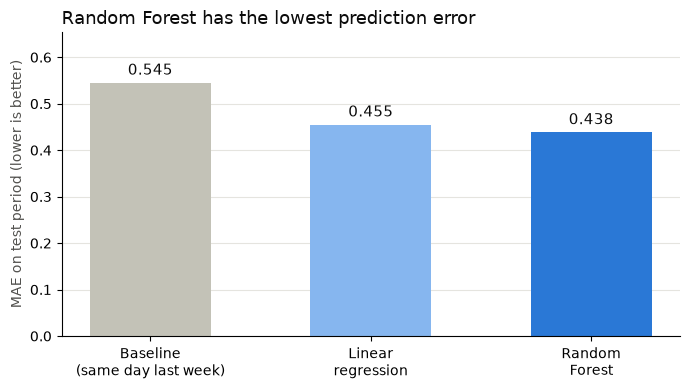

In [8]:
order = ['Baseline (same day last week)', 'Linear regression', 'Random Forest']
labels = ['Baseline\n(same day last week)', 'Linear\nregression', 'Random\nForest']
vals = test_results.loc[order, 'MAE'].values
colors = ['#c3c2b7', '#86b6ef', '#2a78d6']

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, vals, color=colors, width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=11, color='#0b0b0b')
ax.set_title('Random Forest has the lowest prediction error', loc='left', fontsize=13, color='#0b0b0b')
ax.set_ylabel('MAE on test period (lower is better)', color='#52514e')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e5e4df'); ax.set_axisbelow(True)
ax.set_ylim(0, vals.max() * 1.2)
plt.tight_layout()
plt.savefig('fig_model_comparison.png', dpi=200)
plt.show()

## 7. Do promotions, holidays, and weather add value beyond past sales?
This answers the second part of our research question. We train the same Random Forest using **only past sales and day of week**, then compare.

In [9]:
past_only = ['sales_lag1', 'sales_lag7', 'sales_avg7'] + dow_cols
rf_past = RandomForestRegressor(n_estimators=300, max_depth=best_depth, min_samples_leaf=best_leaf,
                                random_state=42, n_jobs=-1).fit(train_valid[past_only], train_valid['sale_amount'])

compare = pd.DataFrame({
    'Random Forest, past sales only': score(test['sale_amount'], rf_past.predict(test[past_only])),
    'Random Forest, all predictors': score(test['sale_amount'], predictions['Random Forest']),
}).T
compare.round(3)

,MAE,RMSE,WAPE (%)
"Random Forest, past sales only",0.439,0.663,36.330
"Random Forest, all predictors",0.438,0.663,36.253


## 8. Which factors matter most?
**Permutation importance:** shuffle one predictor at a time and measure how much the test MAE gets worse. A bigger increase means the model relies on that factor more.

In [10]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, test[features], test['sale_amount'],
                              scoring='neg_mean_absolute_error', n_repeats=10, random_state=42)
importance = pd.Series(perm.importances_mean, index=features)

nice = {'sales_avg7': 'Avg. sales, last 7 days', 'holiday_flag': 'Holiday', 'sales_lag1': 'Sales yesterday',
        'sales_lag7': 'Sales same day last week', 'discount': 'Discount',
        'prev_stock_hour6_22_cnt': 'Stockout hours yesterday', 'prev_avg_temperature': 'Temperature yesterday',
        'prev_avg_humidity': 'Humidity yesterday', 'prev_avg_wind_level': 'Wind yesterday',
        'prev_precpt': 'Rain yesterday', 'activity_flag': 'Promotion activity'}
grouped = importance.rename(lambda c: 'Day of week' if c.startswith('dow_') else nice[c]).groupby(level=0).sum()
grouped = grouped.sort_values(ascending=False)
grouped.round(4)

Avg. sales, last 7 days     0.4343
Holiday                     0.0670
Sales yesterday             0.0285
Sales same day last week    0.0136
Discount                    0.0124
Wind yesterday              0.0004
Humidity yesterday          0.0001
Temperature yesterday       0.0001
Day of week                 0.0000
Rain yesterday             -0.0000
Promotion activity         -0.0002
Stockout hours yesterday   -0.0009
dtype: float64

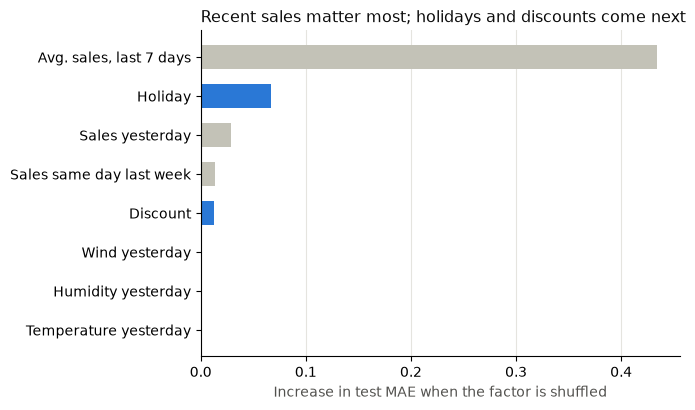

In [11]:
top = grouped.head(8)[::-1]
colors = ['#2a78d6' if name in ('Holiday', 'Discount') else '#c3c2b7' for name in top.index]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color=colors, height=0.6)
ax.set_title('Recent sales matter most; holidays and discounts come next',
             loc='left', fontsize=11.5, color='#0b0b0b')
ax.set_xlabel('Increase in test MAE when the factor is shuffled', color='#52514e')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e5e4df'); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('fig_feature_importance.png', dpi=200)
plt.show()

## 9. Actual vs. predicted sales over the test period (all 100 series added together)

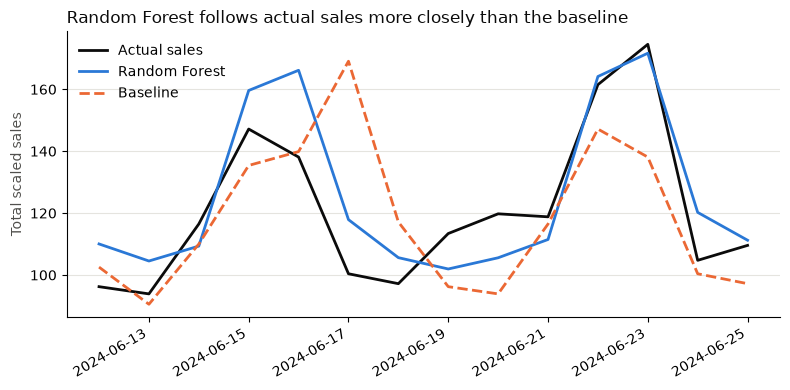

In [12]:
daily = test[['dt', 'sale_amount']].copy()
daily['Random Forest'] = predictions['Random Forest']
daily['Baseline'] = predictions['Baseline (same day last week)']
daily = daily.groupby('dt').sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily.index, daily['sale_amount'], color='#0b0b0b', linewidth=2, label='Actual sales')
ax.plot(daily.index, daily['Random Forest'], color='#2a78d6', linewidth=2, label='Random Forest')
ax.plot(daily.index, daily['Baseline'], color='#eb6834', linewidth=2, linestyle='--', label='Baseline')
ax.set_title('Random Forest follows actual sales more closely than the baseline', loc='left', fontsize=12, color='#0b0b0b')
ax.set_ylabel('Total scaled sales', color='#52514e')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e5e4df'); ax.set_axisbelow(True)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('fig_actual_vs_predicted.png', dpi=200)
plt.show()

In [13]:
test_results.round(3).to_csv('model_results.csv')
print('Saved: model_results.csv, fig_model_comparison.png, fig_feature_importance.png, fig_actual_vs_predicted.png')

Saved: model_results.csv, fig_model_comparison.png, fig_feature_importance.png, fig_actual_vs_predicted.png


## 10. Summary of results
- **Best model:** Random Forest. Test MAE 0.438 vs. 0.545 for the baseline, about 20% lower. WAPE dropped from 45.1% to 36.3%.
- **Linear regression** also beat the baseline (MAE 0.455, about 17% lower), so even a simple model helps.
- **Long stockouts:** with the 107 of 1,400 test rows that had 12+ stockout hours removed, WAPE improves for every model (Random Forest WAPE 32.7%). Those days are harder to predict because sales were limited by empty shelves.
- **Past sales do most of the work.** A Random Forest using only past sales and day of week scored almost the same (MAE 0.439 vs. 0.438). So promotions, holidays, and weather add only a small extra gain for next-day prediction.
- **Most useful factors beyond past sales:** holidays and discounts. Previous-day weather and stockout hours added almost nothing.
- **Limits:** sales are scaled (relative, not revenue), the data covers only 90 days, and results are associations, not proof that a factor causes sales to change.
